# Out-of-Distribution Detection

This notebook inspects the completed Phase 6 artifacts. It does not regenerate scenarios, refit detectors, or modify experiment outputs.

## Purpose And Boundaries

OOD detection asks whether a complete, clean, and verified 13-feature alternative-financial profile is unfamiliar relative to the clean baseline training population. It is not a financial-stress prediction, probability calibration result, evidence-quality score, prediction-uncertainty estimate, or Safety Gate decision.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUTPUT_DIR = PROJECT_ROOT / 'experiments' / 'ood'
sns.set_theme(style='whitegrid')

## Training Reference And Feature Geometry

The reference population is the clean 70% training split from the existing deterministic 70/15/15 split with seed 42. Feature scales differ substantially and several features are highly correlated, so distances use training-only standardization and the covariance-aware method uses Ledoit-Wolf shrinkage.

In [2]:
split_ids = pd.read_csv(OUTPUT_DIR / 'split_applicant_ids.csv')
scores = pd.read_csv(OUTPUT_DIR / 'ood_scores.csv')
summary = pd.read_csv(OUTPUT_DIR / 'scenario_summary.csv')
metadata = json.loads((OUTPUT_DIR / 'metadata.json').read_text())

display(split_ids['split'].value_counts().rename_axis('split').reset_index(name='applicant_count'))
metadata['thresholds']

,split,applicant_count
0,train,7000
1,validation,1500
2,test,1500


{'isolation_forest': 0.535379132900723,
 'shrinkage_mahalanobis': 5.459076558162995,
 'standardized_euclidean': 5.6924565825272735}

## Detector And Scenario Methodology

The experiment fits standardized Euclidean distance, shrinkage Mahalanobis distance, and fixed-seed Isolation Forest on training features only. Higher scores always mean more OOD-like. Each threshold is the 95th percentile of clean validation scores; no test feature or outcome is used for fitting or threshold selection.

Controlled cohorts are derived from clean complete monthly histories and recomputed through the existing feature pipeline. Monetary-scale, temporal-volatility, and transaction-pattern scenarios remain arithmetically valid and carry `clean_verified` evidence-quality metadata.

In [3]:
validation = summary[summary['evaluation_split'].eq('validation')].copy()
validation.groupby('detector')[['threshold', 'clean_false_positive_rate']].first().round(4)

,threshold,clean_false_positive_rate
detector,,
isolation_forest,0.5354,0.05
shrinkage_mahalanobis,5.4591,0.05
standardized_euclidean,5.6925,0.05


## Held-Out Test Evaluation

Each scenario comparison pairs 1,500 clean test applicants with 1,500 controlled OOD counterparts, so the artificial OOD prevalence is 50%. AUROC, AUPRC, clean false-positive rate, and detection rate are OOD metrics only; they do not measure financial-stress prediction.

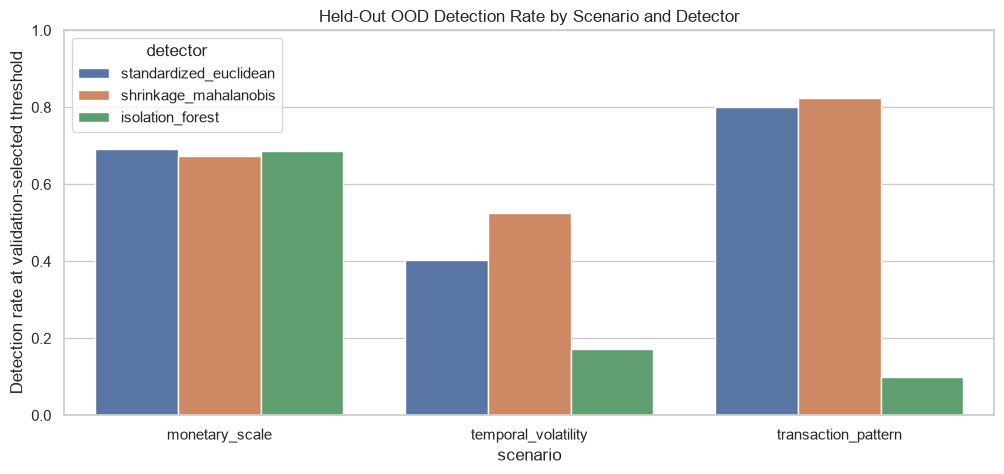

,detector,scenario,severity,auroc,auprc,clean_false_positive_rate,ood_detection_rate
27,standardized_euclidean,monetary_scale,low,0.7544,0.7695,0.0613,0.3460
28,shrinkage_mahalanobis,monetary_scale,low,0.7520,0.7668,0.0613,0.3373
29,isolation_forest,monetary_scale,low,0.7658,0.7700,0.0647,0.3440
30,standardized_euclidean,monetary_scale,medium,0.9373,0.9442,0.0613,0.7760
31,shrinkage_mahalanobis,monetary_scale,medium,0.9321,0.9386,0.0613,0.7453
32,isolation_forest,monetary_scale,medium,0.9369,0.9370,0.0647,0.7627
33,standardized_euclidean,monetary_scale,high,0.9882,0.9894,0.0613,0.9527
34,shrinkage_mahalanobis,monetary_scale,high,0.9860,0.9867,0.0613,0.9387
35,isolation_forest,monetary_scale,high,0.9848,0.9828,0.0647,0.9507
36,standardized_euclidean,temporal_volatility,low,0.5271,0.5235,0.0613,0.0760


In [4]:
test_summary = summary[summary['evaluation_split'].eq('test')].copy()
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=test_summary, x='scenario', y='ood_detection_rate', hue='detector', errorbar=None, ax=ax)
ax.set_ylim(0, 1)
ax.set_title('Held-Out OOD Detection Rate by Scenario and Detector')
ax.set_ylabel('Detection rate at validation-selected threshold')
plt.show()

test_summary[['detector', 'scenario', 'severity', 'auroc', 'auprc', 'clean_false_positive_rate', 'ood_detection_rate']].round(4)

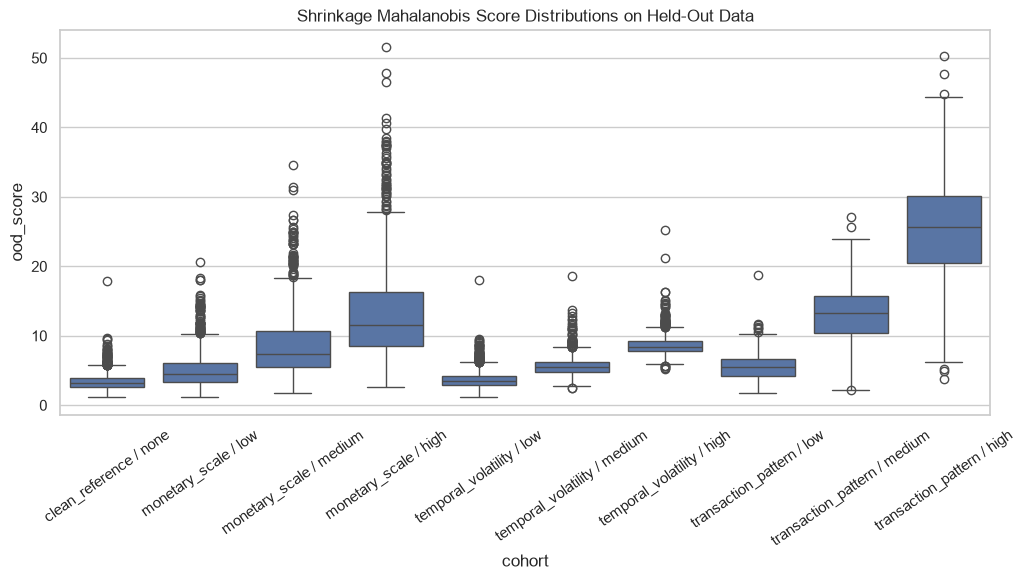

In [5]:
plot_scores = scores[(scores['evaluation_split'].eq('test')) & (scores['detector'].eq('shrinkage_mahalanobis'))].copy()
plot_scores['cohort'] = plot_scores['scenario'] + ' / ' + plot_scores['severity']
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=plot_scores, x='cohort', y='ood_score', ax=ax)
ax.tick_params(axis='x', rotation=35)
ax.set_title('Shrinkage Mahalanobis Score Distributions on Held-Out Data')
plt.show()

## Interpretation And Limitations

The controlled shifts test reproducible detector mechanics, not real-world OOD validity. Performance varies by detector and shift family; it must not be interpreted as evidence of borrower risk, fairness, compliance, calibration quality, or future Safety Gate effectiveness.